# Aufgabe 11.4 – Ausreißerkandidaten der Originalproduktion

Ziel: Auffällige Wochen in der vollständigen Originalspalte `pieces` erkennen,
zählen und mit Seaborn darstellen. Quelle (abgerufen 26.10.2026):
[offizielle Aufgabe](https://noxthot.github.io/ws26_industrial_datascience_manuscript/1_act1/7_self_study_session2.html).
Die [Methodenquelle](https://noxthot.github.io/ws26_industrial_datascience_manuscript/1_act1/2_1_timeseries_decomposition.html)
zeigt die Drei-Sigma-Regel auf STL-Residuen. Datenherkunft und Lizenzgrenzen:
`data/raw/PRODUCTION_SOURCE.md`. KI-Unterstützung: Codex; studentischer Review ausstehend.

## Mathematische Idee und Annahmen
Additiv: y = T + S + R. Als Kandidat gilt eine Woche genau dann, wenn
R < Mittelwert(R) − 3s oder R > Mittelwert(R) + 3s, mit Stichprobenstandardabweichung
s (ddof=1). Strikte Grenzen. Dadurch wird der saisonale Verlauf nicht bereits
aufgrund seiner Höhe als Ausreißer gewertet.

Robuste STL wird auf den unveränderten Originalwerten neu geschätzt. Periode 52,
Saison-LOESS 13, Trend-LOESS 101, Tiefpass-LOESS 53; robust=True,
inner_iter=2, outer_iter=15. Diese Einstellungen sind Modellannahmen, keine
nachgewiesenen Optima. Es wird weder geglättete noch imputierte Produktion verwendet.

In [1]:
from pathlib import Path
import sys, os, json
ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parents[1]
sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".tools/matplotlib"))
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display
from sessions.ch11.production import load_production, SHA256
from sessions.ch11.outliers import detect_outliers
from sessions.ch11.stl_imputation import STL_CONFIG, FIT_CONFIG
OUT = ROOT / "outputs/ch11/exercise_11_4"
OUT.mkdir(parents=True, exist_ok=True)
source = load_production().pieces.copy()
table, lower, upper = detect_outliers(source)
candidates = table.loc[table.outlier_candidate]
summary = {"observations": len(source), "missing": int(source.isna().sum()),
           "outlier_candidates": len(candidates), "fraction_percent": 100*len(candidates)/len(source),
           "lower": lower, "upper": upper, "residual_mean": float(table.residual.mean()),
           "residual_std_ddof1": float(table.residual.std(ddof=1)),
           "negative_candidates": int((candidates.residual < lower).sum()),
           "positive_candidates": int((candidates.residual > upper).sum()),
           "reconstruction_max_abs": float(np.max(np.abs(source-table.trend-table.seasonal-table.residual))),
           "raw_sha256": SHA256, "stl_config": STL_CONFIG, "fit_config": FIT_CONFIG}
display({k:v for k,v in summary.items() if k not in {"stl_config", "fit_config", "raw_sha256"}})
assert source.equals(table.pieces)
assert len(source) == 1044 and not source.isna().any()
np.testing.assert_allclose(table.trend+table.seasonal+table.residual, source, atol=1e-10)
table.to_csv(OUT / "components.csv", index_label="Date")
candidates.to_csv(OUT / "outlier_candidates.csv", index_label="Date")
(OUT / "summary.json").write_text(json.dumps(summary, indent=2)+"\n", encoding="utf-8")

{'observations': 1044,
 'missing': 0,
 'outlier_candidates': 26,
 'fraction_percent': 2.4904214559386975,
 'lower': -85.00239590394462,
 'upper': 75.92048033798203,
 'residual_mean': -4.54095778298129,
 'residual_std_ddof1': 26.82047937365444,
 'negative_candidates': 26,
 'positive_candidates': 0,
 'reconstruction_max_abs': 9.947598300641403e-14}

630

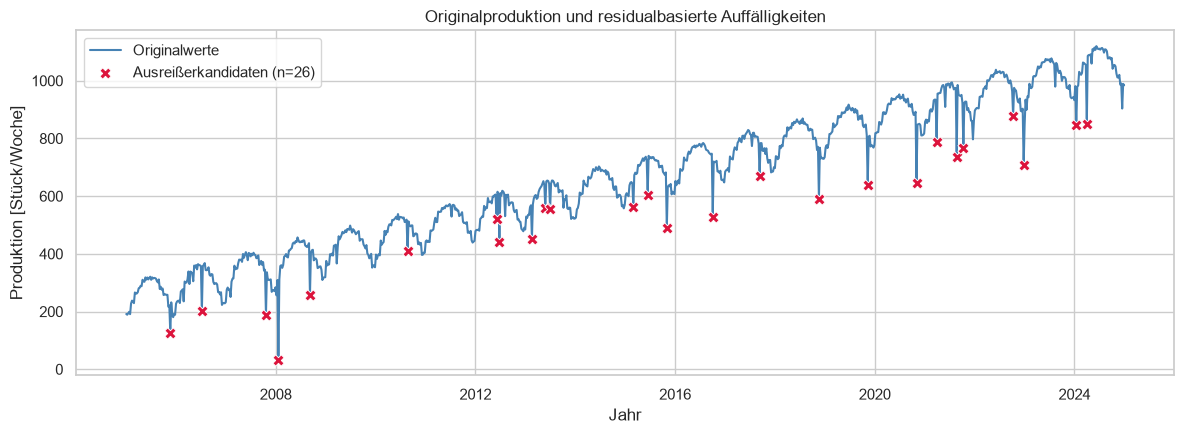

In [2]:
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.lineplot(x=table.index, y=table.pieces, ax=ax, label="Originalwerte", color="steelblue")
sns.scatterplot(x=candidates.index, y=candidates.pieces, ax=ax, color="crimson", marker="X", s=65,
                label=f"Ausreißerkandidaten (n={len(candidates)})", zorder=4)
ax.set(title="Originalproduktion und residualbasierte Auffälligkeiten", xlabel="Jahr", ylabel="Produktion [Stück/Woche]")
fig.tight_layout()
fig.savefig(OUT / "01_original_outliers.png", dpi=160)
plt.show()

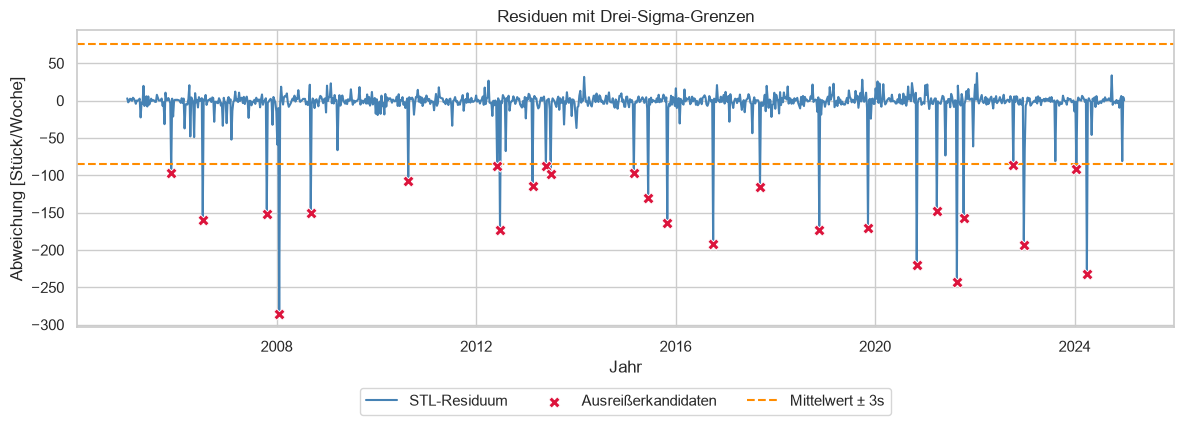

,pieces,residual
Date,,
2005-11-20,126.045,-96.908
2006-07-09,200.707,-159.469
2007-10-21,189.549,-151.175
2008-01-20,33.340,-285.503
2008-09-07,258.462,-150.738
2010-08-22,408.155,-107.524
2012-06-03,521.875,-88.206
2012-06-24,439.649,-173.494
2013-02-17,452.232,-114.308


In [3]:
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.lineplot(x=table.index, y=table.residual, ax=ax, label="STL-Residuum", color="steelblue")
sns.scatterplot(x=candidates.index, y=candidates.residual, ax=ax, color="crimson", marker="X", s=65,
                label="Ausreißerkandidaten", zorder=4)
ax.axhline(lower, color="darkorange", linestyle="--", label="Mittelwert ± 3s")
ax.axhline(upper, color="darkorange", linestyle="--")
ax.set(title="Residuen mit Drei-Sigma-Grenzen", xlabel="Jahr", ylabel="Abweichung [Stück/Woche]")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
fig.tight_layout()
fig.savefig(OUT / "02_residual_thresholds.png", dpi=160)
plt.show()
display(candidates[["pieces", "residual"]].round(3))

## Ergebnis und Grenzen
Es werden 26 von 1.044 Wochen (2,49 %) markiert, alle mit negativem Residuum.
Die Grenzen betragen −85,0024 und 75,9205 Stück/Woche. Auffällig sind damit
starke Unterschreitungen des geschätzten saisonalen Trends; dies beweist keine
Produktionsstörung. Anzahl und Aufteilung nach Vorzeichen stehen oben;
die Tabelle benennt jede markierte Woche. Beobachtung ist die ursprüngliche
Produktion; Trend und Saison sind geschätzt, Residuen sind daraus berechnete
Abweichungen. Die rote Markierung ist eine methodische Klassifikation, kein
Nachweis eines Messfehlers. Alle 1.044 Originalwerte bleiben erhalten.

Die Drei-Sigma-Regel ist eine Heuristik. Ohne belegte Normalverteilung und
Unabhängigkeit folgt daraus keine kalibrierte Fehlalarmwahrscheinlichkeit.
Auch einzelne starke Abweichungen beeinflussen die Residuenstreuung. Die robuste
STL reduziert deren Einfluss auf die Glättung, garantiert aber keine korrekte
Klassifikation. Parameter, Randbereiche und die Näherung eines Jahres durch
52 Wochen beeinflussen das Ergebnis. Es gibt keine verifizierten Fehlerlabels;
Sensitivität und Spezifität können daher nicht bestimmt werden. Keine automatische
Bereinigung und keine kausale Erklärung.

Lernfragen: Ist die Trennung von saisonalem Niveau und ungewöhnlicher Abweichung
plausibel? Sind die markierten Wochen fachlich auffällig? Wie könnten andere
Schwellen oder STL-Annahmen die Auswahl verändern?